<a href="https://colab.research.google.com/github/Chaitanyaperumalla/CODSOFT-PYTHON-PROGRAMMING/blob/main/fraud%20detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


In [3]:
data = pd.read_csv('d.csv')
data.head()


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0.0,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0.0,0.0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1.0,0.0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1.0,0.0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0.0,0.0


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 899846 entries, 0 to 899845
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   step            899846 non-null  int64  
 1   type            899846 non-null  object 
 2   amount          899846 non-null  float64
 3   nameOrig        899846 non-null  object 
 4   oldbalanceOrg   899846 non-null  float64
 5   newbalanceOrig  899845 non-null  float64
 6   nameDest        899845 non-null  object 
 7   oldbalanceDest  899845 non-null  float64
 8   newbalanceDest  899845 non-null  float64
 9   isFraud         899845 non-null  float64
 10  isFlaggedFraud  899845 non-null  float64
dtypes: float64(7), int64(1), object(3)
memory usage: 75.5+ MB


In [6]:
data.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,899846.000000,8.998460e+05,8.998460e+05,8.998450e+05,8.998450e+05,8.998450e+05,899845.000000,899845.0
mean,23.093213,1.632822e+05,8.850914e+05,9.058727e+05,9.869313e+05,1.133189e+06,0.000553,0.0
std,11.633155,2.633378e+05,2.995245e+06,3.032119e+06,2.311010e+06,2.438829e+06,0.023519,0.0
min,1.000000,1.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.0
25%,14.000000,1.305269e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.0
50%,19.000000,8.103139e+04,1.625400e+04,0.000000e+00,1.325737e+05,2.316383e+05,0.000000,0.0
75%,36.000000,2.208273e+05,1.459935e+05,1.873896e+05,9.247566e+05,1.177900e+06,0.000000,0.0
max,42.000000,1.000000e+07,3.893942e+07,3.894623e+07,4.148270e+07,4.205466e+07,1.000000,0.0


In [8]:
obj = (data.dtypes == 'object')
object_col = list(obj[obj].index)
print("Categorical variables are:", len(object_col))

int_ = (data.dtypes == 'int')
num_col = list(int_[int_].index)
print("Integer variables are:", len(num_col))

fl = (data.dtypes == 'float')
fl_col = list(fl[fl].index)
print("Float variables are:", len(fl_col))


Categorical variables are: 3
Integer variables are: 1
Float variables are: 7


<Axes: xlabel='type', ylabel='count'>

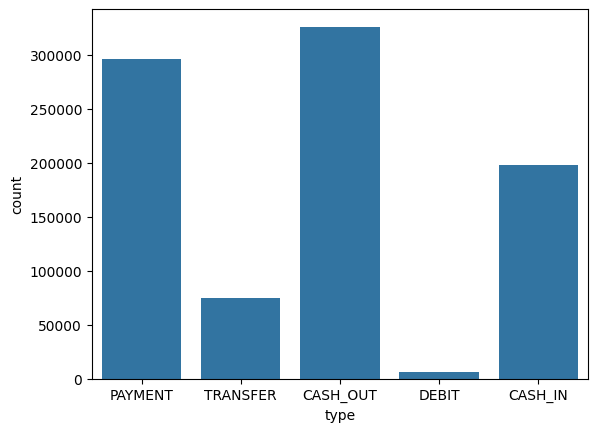

In [9]:
sns.countplot(x='type', data=data)

<Axes: xlabel='type', ylabel='amount'>

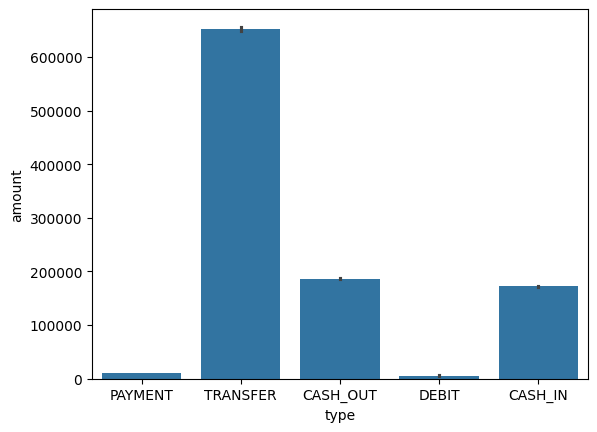

In [10]:
sns.barplot(x='type', y='amount', data=data)

In [11]:
data['isFraud'].value_counts()

,count
isFraud,
0.0,899347
1.0,498


<ipython-input-12-d1bba932735e>:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['step'], bins=50)


<Axes: xlabel='step', ylabel='Density'>

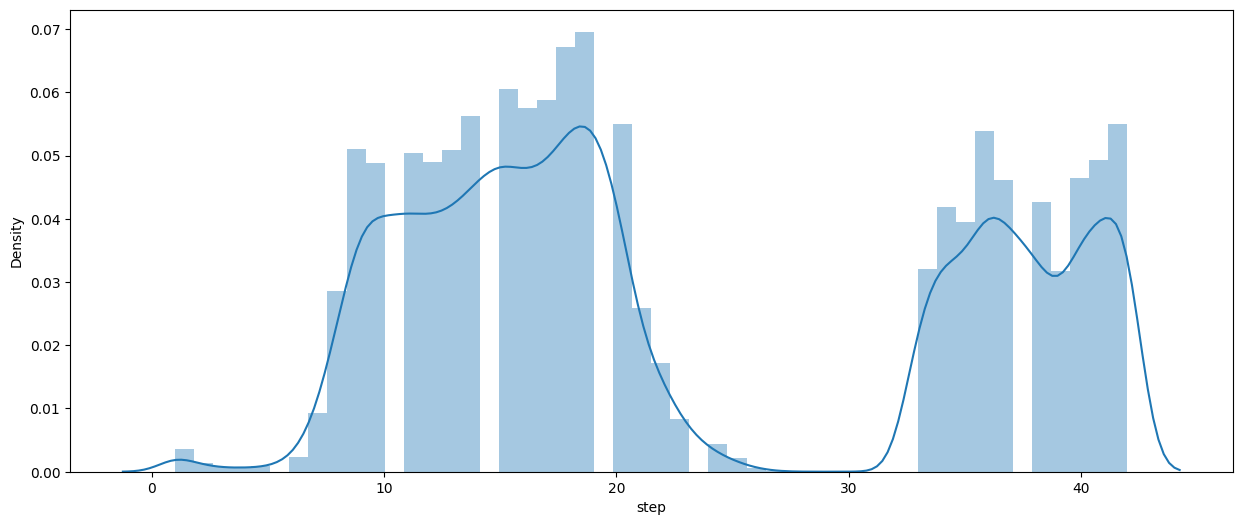

In [12]:
plt.figure(figsize=(15, 6))
sns.distplot(data['step'], bins=50)

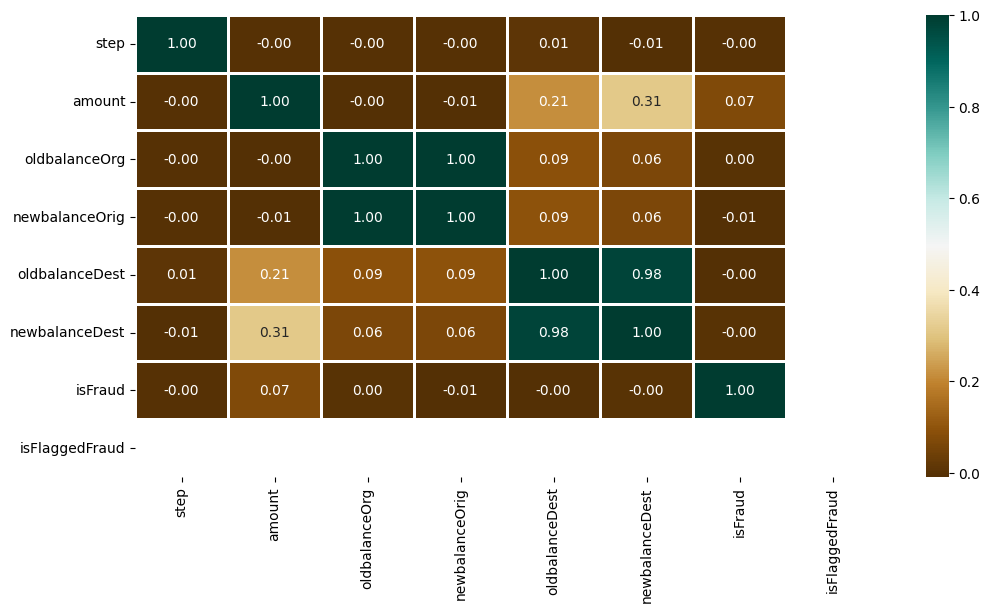

In [14]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

numerical_data = data.select_dtypes(include=np.number)

plt.figure(figsize=(12, 6))
sns.heatmap(numerical_data.corr(),
            cmap='BrBG',
            fmt='.2f',
            linewidths=2,
            annot=True)
plt.show()

In [15]:
type_new = pd.get_dummies(data['type'], drop_first=True)
data_new = pd.concat([data, type_new], axis=1)
data_new.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,CASH_OUT,DEBIT,PAYMENT,TRANSFER
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0.0,0.0,False,False,True,False
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0.0,0.0,False,False,True,False
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1.0,0.0,False,False,False,True
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1.0,0.0,True,False,False,False
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0.0,0.0,False,False,True,False


In [16]:
X = data_new.drop(['isFraud', 'type', 'nameOrig', 'nameDest'], axis=1)
y = data_new['isFraud']

In [17]:
X.shape, y.shape

((899846, 11), (899846,))

In [18]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
	X, y, test_size=0.3, random_state=42)

In [19]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score as ras
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

In [21]:
!pip install scikit-learn
import pandas as pd
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score as ras
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
# Impute missing values using SimpleImputer
from sklearn.impute import SimpleImputer

# Create a SimpleImputer instance to replace NaN with the mean of the

In [ ]:
from google.colab import drive
drive.mount('/content/drive')